In [1]:
import numpy as np
import matplotlib.pyplot as plt

# The Python implementation of the function above is rather slow
# We made a C++ library that implements the function above much faster
# To run this library one needs to load cpp_routines which will, in turn, 
# load a library routines_lib.so from the folder RewardCalc
# If the library file is not there the loader will attempt to run Makefile in RewardCalc
# The library function expected_reward_table is called in exactly the same way

import sys
sys.path.append('../Simulations')
from cpp_routines import *

In [2]:
# We have coded up a special C++ function that finds the minimal number of remaining presses
# For which it is more optimal to leave the current button and explore further
# For given number of wins and fails
# If no such number exists for the given process duration, the function returns 0

trans_table = optimal_transition_table(10, 10, 2000, prior=(1, 1))
print(trans_table)

[[   1    1    1    1    1    1    1    1    1    1]
 [   0    1    1    1    1    1    1    1    1    1]
 [   0   12    1    1    1    1    1    1    1    1]
 [   0   39    5    1    1    1    1    1    1    1]
 [   0   94   10    3    1    1    1    1    1    1]
 [   0  190   19    6    3    1    1    1    1    1]
 [   0  344   30   10    5    2    1    1    1    1]
 [   0  578   45   14    7    4    2    1    1    1]
 [   0  915   63   20    9    5    3    2    1    1]
 [   0 1385   86   27   13    7    5    3    2    1]]


In [3]:
run_time = 100
number_of_runs = 1000
# button = Button('Bernoulli', prior=(1, 1))
button = Button('Truncated', truncation=0.9)
policy = Policy('Bernoulli', prior=(1, 1))
# policy = Policy('Truncated', truncation=0.9)
# policy = Policy('Difference', difference=4)

trial_record = record_full_trials(run_time, number_of_runs, button, policy)

#Taking only wins and fails
trial_record = trial_record[:,:,[0,3]]

In [4]:
#subjects_decisions contains subject decisions for each subject
#the first column contains number of accumulated wins, the second contains accumulated fails
#the third is boolean and contains 1 if subject decided to change the button and 0 if subject decided to stay
#the fourth contains the number of remaining presses
subjects_decisions = []
#subjects_button_activity contains accumulated buttons wins, fails and remaining presses for all the subjects per button
subjects_button_activity = []
for record in trial_record:
    button_split = [record[record[:,0]==k,1] for k in np.unique(record[:,0])]
    decisions = [np.vstack([np.cumsum(elt),
                                np.arange(1,len(elt)+1)-np.cumsum(elt),
                                np.eye(1,M=len(elt),k=len(elt)-1)]).T for elt in button_split]
    button_split_pos = np.cumsum([len(el) for el in decisions])[:-1]
    decisions = np.concatenate(decisions)
    decisions = np.c_[decisions, np.arange(len(decisions))[::-1]]
    subjects_decisions.append(decisions[:-1])
    subjects_button_activity.append(np.split(decisions[:,[0,1,3]], button_split_pos))
    
decisions = np.concatenate(subjects_decisions)
decisions = decisions[np.lexsort((decisions[:,3], decisions[:,2], decisions[:,1], decisions[:,0]))].astype(int)

In [5]:
out1, out2 = np.unique(decisions[:,:2], axis=0, return_counts=True)
total_counts = np.c_[out1, out2]

In [6]:
total_counts[total_counts[:,0]<10]

array([[   0,    1, 9841],
       [   1,    0, 8269],
       [   1,    1, 3305],
       [   2,    0, 4959],
       [   2,    1, 1576],
       [   2,    2,    9],
       [   3,    0, 3381],
       [   3,    1,  965],
       [   3,    2,   62],
       [   3,    3,    4],
       [   4,    0, 2422],
       [   4,    1,  718],
       [   4,    2,  214],
       [   4,    3,    5],
       [   5,    0, 1799],
       [   5,    1,  898],
       [   5,    2,  266],
       [   5,    3,    7],
       [   5,    4,    4],
       [   5,    5,    1],
       [   6,    0, 1357],
       [   6,    1,  956],
       [   6,    2,  258],
       [   6,    3,   13],
       [   6,    4,    2],
       [   7,    0, 1036],
       [   7,    1,  907],
       [   7,    2,  245],
       [   7,    3,   33],
       [   7,    4,    2],
       [   8,    0,  838],
       [   8,    1,  852],
       [   8,    2,  277],
       [   8,    3,   41],
       [   8,    4,   10],
       [   9,    0,  680],
       [   9,    1,  749],
 

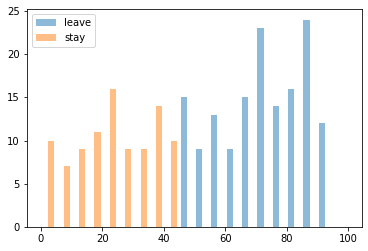

In [7]:
wins, fails = 7, 2
choise = decisions[np.logical_and(decisions[:,0]==wins,decisions[:,1]==fails)][:,2:]
leave = choise[choise[:,0]==1][:,1]
stay = choise[choise[:,0]==0][:,1]

plt.hist([leave, stay], alpha=0.5, label=["leave", "stay"], range=[0.0, 100.0], bins=20)
plt.legend(loc="upper left")
plt.show()

The average number of buttons explored is 18.124
The average reward received is 72.416
Out of 1000 subjects in total 891 subjects (or 89.10%) got the largest contribution from the last button
The average contribution of the button with the largest contribution is 67.23 %


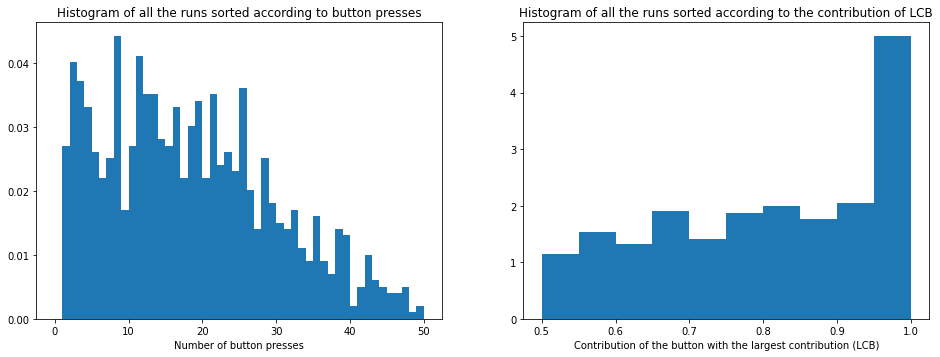

In [8]:
#Contribution (number of wins) for each button for each subject
contributions = [[el[-1,0] for el in subject] for subject in subjects_button_activity]
#Total number of button pressed
num_buttons = np.array([len(subject) for subject in contributions], dtype=np.int)
#Index of the button with largest contribution
max_button_index = np.array([subject.index(max(subject)) for subject in contributions], dtype=np.int)
#Number of runs where the final button was the button with the largest contribution
num_last_largest_contr = np.count_nonzero(max_button_index==(num_buttons-1))
#Ratio of largest button contribution to total contribution
top_button_to_all = np.array([max(subject)/sum(subject) for subject in contributions])

print("The average number of buttons explored is " + str(np.sum(num_buttons)/len(num_buttons)))
print("The average reward received is " + str(np.sum([sum(subject) for subject in contributions])/len(contributions)))
print("Out of " + str(len(contributions)) + " subjects in total " + str(num_last_largest_contr) + 
            " subjects (or " + "%.2f" % (100*num_last_largest_contr/len(contributions)) + 
              "%) got the largest contribution from the last button")
print("The average contribution of the button with the largest contribution is " + 
          "%4.2f" % (100*np.mean(top_button_to_all)) + " %")

fig = plt.figure(figsize=(16,12))
ax = fig.add_subplot(221)
ax.set_title("Histogram of all the runs sorted according to button presses")
ax.set_xlabel("Number of button presses")
ax.hist(num_buttons, density=True, bins=50, range=(0, 50));

ax = fig.add_subplot(222)
ax.set_title("Histogram of all the runs sorted according to the contribution of LCB")
ax.set_xlabel("Contribution of the button with the largest contribution (LCB)")
ax.hist(top_button_to_all, density=True, bins=10, range=(0.5,1));

Total number of stay decisions is 53571
Total number of leave decisions is 3964


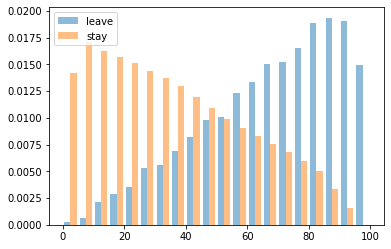

In [9]:
wins_more_fails = decisions[np.logical_and(decisions[:,0] > decisions[:,1], decisions[:,1] > 0)]
#wins_more_fails = decisions[np.logical_and(decisions[:,0] == 2*decisions[:,1], decisions[:,1] > 0)]
wmf_stay = wins_more_fails[wins_more_fails[:,2] == 0]
wmf_leave = wins_more_fails[wins_more_fails[:,2] == 1]

print("Total number of stay decisions is " + str(len(wmf_stay)))
print("Total number of leave decisions is " + str(len(wmf_leave)))

plt.hist([wmf_leave[:,3], wmf_stay[:,3]], alpha=0.5, label=["leave", "stay"], range=[0.0, 100.0], bins=20, density=True)
plt.legend(loc="upper left")
plt.show()